In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


In [48]:
df=pd.read_csv('cleaned_used_cars_dataset.csv')

## 📊 Distribution of Car Prices

- **Right-skewed**: most cars are priced low, with a few very expensive ones.
- Median is about **0.55M EGP**, and most prices fall between **0.33M and 0.95M**.
- The box plot flags about **4% of listings (115 cars) above ~1.8M EGP**, but these are **genuine prices, not data errors**: about **83%** of them are **Mercedes-Benz and BMW**, and all are **2020 or newer models** (the most expensive is a 2026 Mercedes C200 at ~3.8M).
- The right skew exists because the dataset is mostly **older, lower-priced cars**, with only a small number of new premium cars.
- **Takeaway:** These high prices should be **kept**. Consider a **log transformation** before modeling to reduce the skew.

In [49]:
fig = px.histogram(
    df, x='price_egp', nbins=40,
    marginal='box',                       
    title='Distribution of Car Prices',
    labels={'price_egp': 'Price (EGP)'}
)
fig.update_layout(bargap=0.05, yaxis_title='Frequency')
fig.show()

## 📉 Mileage vs Price

- **Moderate negative relationship** (correlation ≈ **-0.55**): higher mileage tends to mean lower price.
- Almost all cars (~99%) are below **~300K km**. Only **2 listings exceed 500K km**: a Fiat Tipo 2014 at **999,999 km** and a Renault Logan 2020 at **950,000 km**. The first looks like a placeholder value and both are likely **data entry errors**.
- The straight OLS line is a poor fit at high mileage: it **predicts negative prices beyond ~270K km**.
- **Takeaway:** Consider removing the mileage outliers (e.g., keep < 500K km), which affects only those 2 listings.

In [50]:
#pip install statsmodels
fig = px.scatter(
    df, x='mileage_km', y='price_egp',
    trendline='ols',                    
    opacity=0.5,
    title='Mileage vs Price',
    labels={'mileage_km': 'Mileage (km)', 'price_egp': 'Price (EGP)'}
)
fig.show()

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [52]:
df=pd.read_csv('cleaned_used_cars_dataset.csv')
print(df.shape)
df.head()

(2901, 18)


,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
0,CAR-52762,MG,Zs,2021,64900.0,Automatic,Diesel,1500.0,SUV,Black,Giza,Individual,No,1.0,Fair,8.0,655000,Yes
1,CAR-52678,Kia,Cerato,2023,42100.0,Automatic,Diesel,1600.0,Sedan,Grey,Giza,Individual,No,1.0,Good,12.0,1012000,No
2,CAR-52822,Skoda,Octavia,2009,224500.0,Automatic,Petrol,1400.0,Sedan,Silver,Banha,Dealer,Yes,2.0,Fair,11.0,229000,No
3,CAR-51133,Fiat,Tipo,2019,103800.0,Automatic,Petrol,1600.0,Sedan,Silver,Alexandria,Individual,No,2.0,Fair,7.0,319000,No
4,CAR-51465,Mitsubishi,Lancer,2022,50200.0,Manual,Hybrid,1600.0,Sedan,White,Cairo,Individual,No,2.0,Fair,8.0,425000,No


In [53]:
print("\nTarget values:")
print(df["sold_within_30_days"].value_counts(dropna=False))


Target values:
sold_within_30_days
No     1582
Yes    1319
Name: count, dtype: int64


## 🔥 Correlation Heatmap — Numerical Features — Key Insights

- **`year` has the strongest positive link with price (~0.57)**, followed by `engine_cc` (~0.29): newer cars and bigger engines tend to cost more.
- **`mileage_km` is negatively correlated with price (~-0.55)**: the more a car has been driven, the cheaper it tends to be.
- **`year` and `mileage_km` are strongly correlated with each other (~-0.88)**, so they carry almost the same information. Keep an eye on multicollinearity in linear models.
- **`previous_owners`** has a mild negative link with price (~-0.23) and rises with older, higher-mileage cars.
- **`photos_count` is almost uncorrelated with everything (~0)**, so it is unlikely to help explain price.
- These are linear associations only; they do not prove cause and effect.

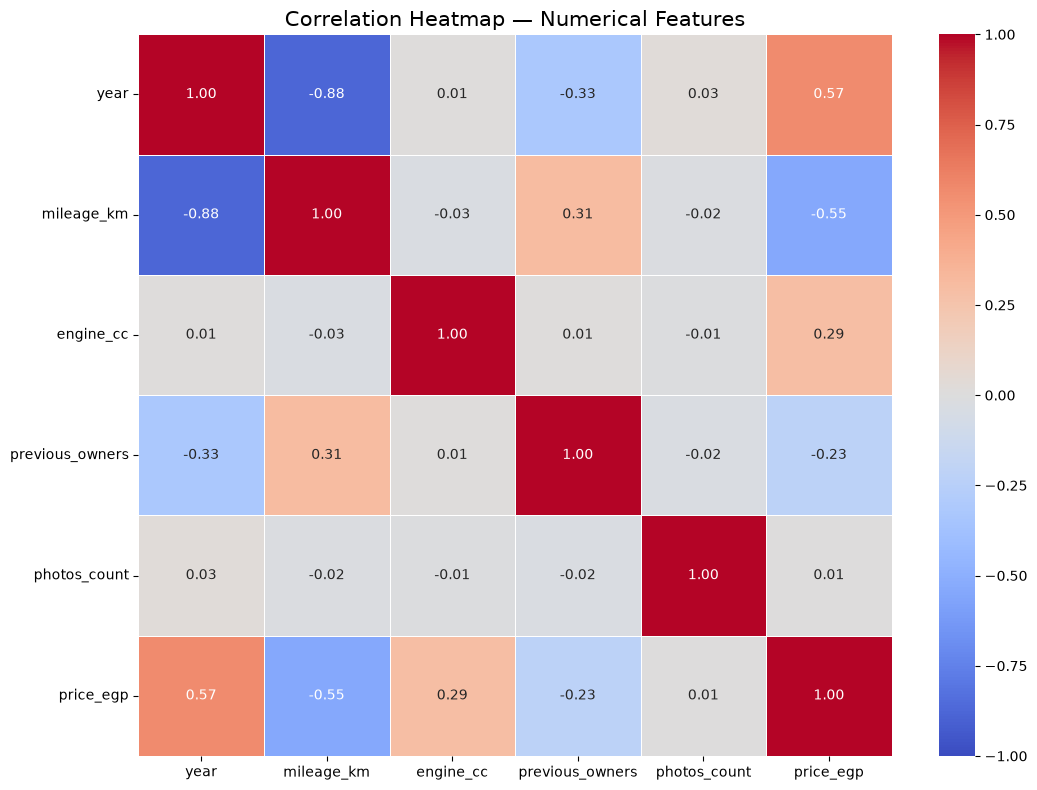

In [54]:
numerical_cols = [
    "year",
    "mileage_km",
    "engine_cc",
    "previous_owners",
    "photos_count",
    "price_egp"
]


corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap — Numerical Features", fontsize=15)
plt.tight_layout()
plt.show()

## 🎯 Correlation Heatmap — Numerical Features vs Target — Key Insights

- **All correlations with `sold_within_30_days` are weak** (none exceeds ±0.20), so no single numerical feature explains whether a car sells quickly.
- **`mileage_km` has the strongest negative link (~-0.20)**: cars with lower mileage are somewhat more likely to be sold within 30 days.
- **`year` has the strongest positive link (~+0.19)**: newer cars tend to sell faster.
- **`price_egp` shows a slightly positive link (~+0.10)**. This is probably because newer cars are both pricier and quicker to sell, not because higher prices speed up sales.
- `photos_count` (~+0.08), `engine_cc` (~+0.05), and `previous_owners` (~-0.07) are close to zero.
- **Takeaway:** categorical features (brand, condition, city, etc.) and combinations of features are needed to predict the target better.

In [55]:
df["sold_within_30_days_num"] = (
    df["sold_within_30_days"]
    .map({"No": 0, "Yes": 1})
)

In [56]:
target_cols = numerical_cols + ["sold_within_30_days_num"]

In [57]:
target_corr = (
    df[target_cols]
    .corr()["sold_within_30_days_num"]
    .drop("sold_within_30_days_num")
    .sort_values()
)

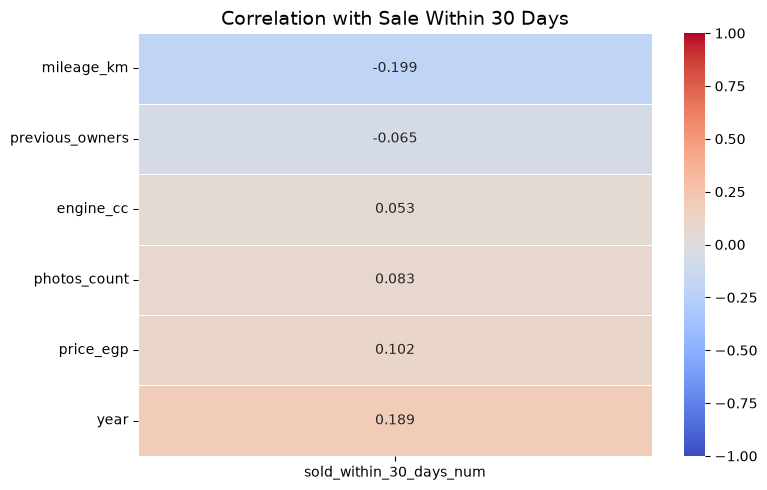

In [58]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    target_corr.to_frame(),
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation with Sale Within 30 Days", fontsize=14)
plt.tight_layout()
plt.show()

## 📈 Scatter Plot — Year vs Price — Key Insights

- **Price rises with manufacturing year** (correlation ~0.57): median prices go from about **0.18M EGP** for 2005–2006 cars to roughly **1.2M EGP** for 2025 cars.
- The increase is much sharper from about **2014 onward**; older cars (before ~2013) stay in a low and narrow price band.
- **Most listings are from 2016–2024**, while very old cars (e.g., 1970 and 1985) are single listings that sit apart from the main cloud.
- Cars marked **“Yes”** (sold within 30 days) are concentrated toward newer years, but both groups overlap across the whole range, so year alone does not decide whether a car sells.
- Several brands share the same year at very different prices (e.g., premium vs. economy brands). Use the hover details to inspect them.

In [59]:
fig = px.scatter(
    df,
    x="year",
    y="price_egp",
    color="sold_within_30_days",
    hover_data=["brand", "model", "mileage_km", "engine_cc"],
    title="Scatter Plot — Year vs Price",
    labels={
        "year": "Manufacturing Year",
        "price_egp": "Price (EGP)",
        "sold_within_30_days": "Sold Within 30 Days"
    },
    opacity=0.7
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5
)

fig.show()

## 📊 Line Chart — Sales Rate by Year — Key Insights

- **Newer cars sell faster**: the sales rate goes from about **16–23%** for 2005–2008 cars to about **66%** for 2025 cars.
- The upward trend is fairly steady from 2014 onward, rising from about **26%** (2014) to **56%** (2024).
- The overall average is about **45.5%**, and cars from **2019 and later** are at or above this level.
- **Ignore the spikes at the edges**: 1970 and 1985 show 100% and 2026 shows 50%, but each is based on only 1–6 listings, so they are noise.
- The pattern is an association: newer cars are also pricier and have lower mileage, so year is not the only factor behind faster sales.

In [60]:
df["sold_num"] = df["sold_within_30_days"].map({
    "Yes": 1,
    "No": 0
})

sales_year = df.groupby("year")["sold_num"].mean().reset_index()

sales_year["sold_num"] *= 100

fig = px.line(
    sales_year,
    x="year",
    y="sold_num",
    markers=True,
    title="Sales Rate by Year",
    labels={
        "year": "Manufacturing Year",
        "sold_num": "Sales Rate (%)"
    }
)

fig.update_layout(template="plotly_white")
fig.show()

## 🚗 Number of Cars by Brand — Key Insights

- **Hyundai is the most listed brand with 504 cars (~17%)**, followed by **Toyota (399)** and **Nissan (306)**. Together, these three make up about **42%** of the dataset.
- **Kia (258), Chevrolet (213), and MG (195)** form the middle group.
- **Mitsubishi (106), Mercedes-Benz (122), and BMW (134)** have the fewest listings, so premium brands are a small part of the data.
- The data is **imbalanced across brands**: results for small brands (e.g., Mitsubishi) are less reliable than for large ones.
- The chart shows listing counts only; it does not reflect real market share unless the dataset is representative.

In [61]:
brand_counts = df["brand"].value_counts().reset_index()
brand_counts.columns = ["brand", "car_count"]

fig = px.bar(
    brand_counts,
    x="brand",
    y="car_count",
    title="Number of Cars by Brand",
    labels={
        "brand": "Brand",
        "car_count": "Number of Cars"
    },
    text="car_count"
)

fig.update_traces(textposition="outside")

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    xaxis_tickangle=-45
)

fig.show()

## 🏆 Sales Rate by Brand — Key Insights

- **Kia has the highest sales rate (~52%)**, followed closely by **Chery (~50%)** and **Hyundai (~49%)**.
- **Fiat has the lowest rate (~33%)**, well below the overall average of about **45.5%**; **Mitsubishi (~41%)** and **Nissan (~42%)** are also on the lower side.
- The gap between the best and worst brand is about **20 percentage points**, so brand does matter for how quickly a car sells.
- **Premium brands are not faster sellers**: BMW (~48%) and Mercedes-Benz (~44%) sit close to the average, so a higher price level does not guarantee a quicker sale.
- Brands have different numbers of listings (106 to 504), so small differences between brands near the middle should not be over-interpreted.

In [62]:
sales_brand = (
    df.groupby("brand")["sold_num"]
    .mean()
    .mul(100)
    .reset_index()
)

sales_brand = sales_brand.sort_values(
    "sold_num",
    ascending=True
)

fig = px.bar(
    sales_brand,
    x="sold_num",
    y="brand",
    orientation="h",
    title="Sales Rate by Brand",
    labels={
        "brand": "Brand",
        "sold_num": "Sales Rate (%)"
    }
)

fig.update_layout(
    template="plotly_white",
    xaxis_ticksuffix="%"
)

fig.show()

## 📚 Import Required Libraries

This cell imports the Python libraries used throughout the notebook:

- **Pandas** helps load and organize the car dataset.
- **Matplotlib** and **Seaborn** are available for plotting.

These imports prepare the environment for data loading and visualization.

In [63]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px



## 📂 Load the Cleaned Dataset

This cell reads the cleaned used-cars dataset into a Pandas DataFrame named `df`.

- The CSV file must be available in the notebook's working directory.
- `df.head()` displays the first five rows so we can quickly inspect the dataset and confirm that it loaded correctly.

In [64]:

import pandas as pd

df = pd.read_csv("cleaned_used_cars_dataset.csv")

df.head()


,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
0,CAR-52762,MG,Zs,2021,64900.0,Automatic,Diesel,1500.0,SUV,Black,Giza,Individual,No,1.0,Fair,8.0,655000,Yes
1,CAR-52678,Kia,Cerato,2023,42100.0,Automatic,Diesel,1600.0,Sedan,Grey,Giza,Individual,No,1.0,Good,12.0,1012000,No
2,CAR-52822,Skoda,Octavia,2009,224500.0,Automatic,Petrol,1400.0,Sedan,Silver,Banha,Dealer,Yes,2.0,Fair,11.0,229000,No
3,CAR-51133,Fiat,Tipo,2019,103800.0,Automatic,Petrol,1600.0,Sedan,Silver,Alexandria,Individual,No,2.0,Fair,7.0,319000,No
4,CAR-51465,Mitsubishi,Lancer,2022,50200.0,Manual,Hybrid,1600.0,Sedan,White,Cairo,Individual,No,2.0,Fair,8.0,425000,No


## 💰 Top 15 Brands by Median Price — Key Insights

- **Mercedes-Benz and BMW lead the chart**, with median prices of about **1.49M EGP** and **1.34M EGP**, respectively.
- **Toyota, Chery, and Skoda** sit in the next-highest group, with median prices around **833K, 788K, and 763K EGP**.
- **Chevrolet has the lowest median price** at roughly **253K EGP**; Mitsubishi, Renault, Fiat, and Nissan also appear toward the lower end.
- The gap between the highest-priced brands and the lower-priced brands is substantial, suggesting that **brand choice is strongly associated with the typical listed price** in this dataset.
- The dataset contains only **13 brands**, so the “Top 15” chart actually displays **all of them**, not a filtered selection.
- These are **median asking prices**, not necessarily final sale prices.

In [65]:

import plotly.express as px

brand_prices = df.groupby("brand")["price_egp"].median()
brand_prices = brand_prices.sort_values().tail(15)

fig = px.bar(
    x=brand_prices.values,
    y=brand_prices.index,
    orientation="h",
    title="Top 15 Brands by Median Price",
    labels={
        "x": "Median Price (EGP)",
        "y": "Brand"
    },
    text=brand_prices.values
)

fig.update_traces(
    texttemplate="%{text:,.0f} EGP",
    textposition="outside",
    hovertemplate="<b>%{y}</b><br>Median Price: %{x:,.2f} EGP<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Median Price (EGP)",
    yaxis_title="Brand",
    yaxis=dict(categoryorder="total ascending"),
    height=600,
    showlegend=False
)

fig.show()

## ⛽ Fuel Type by Transmission — Key Insights

- **Petrol cars dominate the dataset** across every recorded transmission category (about **1,931 listings**, roughly two-thirds of the data). The largest group is petrol with automatic transmission (**1,348 listings**), followed by petrol with manual transmission (**542 listings**).
- **Automatic transmission is more common than manual** for petrol (1,348 vs. 542), diesel (360 vs. 140), and hybrid cars (291 vs. 106).
- Diesel listings are the next-largest fuel group (**507 in total**), with **360 automatic** and **140 manual** cars.
- Hybrid cars are the smallest known fuel group (**406 in total**), with **291 automatic** and **106 manual**.
- Records with an unknown fuel type (**57**) or unknown transmission (**57**) are relatively few. Still, the chart shows listing counts only; it does not tell us the market-wide popularity of each category unless the dataset is representative.

In [66]:

import pandas as pd
import plotly.express as px

fuel = pd.crosstab(df["fuel_type"], df["transmission"])

fuel_long = fuel.reset_index().melt(
    id_vars="fuel_type",
    var_name="transmission",
    value_name="count"
)

fig = px.bar(
    fuel_long,
    x="fuel_type",
    y="count",
    color="transmission",
    title="Fuel Type by Transmission",
    labels={
        "fuel_type": "Fuel Type",
        "count": "Count",
        "transmission": "Transmission"
    },
    barmode="stack",
    text="count"
)

fig.update_traces(
    hovertemplate=(
        "Fuel Type: %{x}<br>"
        "Transmission: %{fullData.name}<br>"
        "Count: %{y}<extra></extra>"
    )
)

fig.update_layout(
    template="plotly_white",
    xaxis_tickangle=-45,
    height=500,
    legend_title_text="Transmission",
    hovermode="x unified"
)

fig.show()

## 🚗 Cars Sold Within 30 Days — Key Insights

- **1,582 listings (about 54.5%) are marked “No”**, meaning they were not recorded as sold within 30 days.
- **1,319 listings (about 45.5%) are marked “Yes”**, meaning they were recorded as sold within 30 days.
- The “No” group is larger by **263 listings**, so in this dataset, fewer than half of the cars have a recorded sale within the 30-day window.
- This chart describes the recorded outcome only. It does not identify *why* a car sold quickly; price, condition, brand, location, and listing quality would need further analysis.

In [67]:

import plotly.express as px

sales_counts = df["sold_within_30_days"].value_counts().dropna()

fig = px.pie(
    names=sales_counts.index,
    values=sales_counts.values,
    title="Cars Sold Within 30 Days",
    hole=0,  # Pie chart عادي، خليها 0.4 لو عايز Donut
)

fig.update_traces(
    textinfo="label+percent",
    textposition="inside",
    hovertemplate=(
        "Status: %{label}<br>"
        "Count: %{value}<br>"
        "Percentage: %{percent}<extra></extra>"
    ),
    sort=False
)

fig.update_layout(
    template="plotly_white",
    height=600
)

fig.show()


## 📉 Price vs Mileage — Key Insights

- The scatter plot shows a **clear negative relationship** between mileage and price: cars with higher mileage generally tend to have lower prices. In the plotted records, the overall correlation is approximately **−0.55**, indicating a moderate negative association.
- Cars marked **“Yes”** have a lower median mileage (about **72,900 km**) and a higher median price (about **621,000 EGP**) than cars marked **“No”** (about **97,650 km** and **495,500 EGP**).
- The two groups still overlap considerably, so mileage and sale status alone cannot explain a car’s price or predict whether it will sell within 30 days.
- **Two listings in the “No” group have extreme mileage**: a Fiat Tipo 2014 at **999,999 km** and a Renault Logan 2020 at **950,000 km**. The first looks like a placeholder value, so both should be checked for data-entry issues before modeling. All other cars are below ~375K km.
- The relationship is an association, not proof that mileage alone causes lower prices.

In [68]:

import plotly.express as px

fig = px.scatter(
    df,
    x="mileage_km",
    y="price_egp",
    color="sold_within_30_days",
    title="Price vs Mileage",
    labels={
        "mileage_km": "Mileage (km)",
        "price_egp": "Price (EGP)",
        "sold_within_30_days": "Sold Within 30 Days"
    },
    hover_data=["brand", "fuel_type", "transmission"]
)

fig.update_layout(
    template="plotly_white",
    height=550,
    xaxis_title="Mileage (km)",
    yaxis_title="Price (EGP)",
    legend_title_text="Sold Within 30 Days"
)

fig.update_traces(
    marker=dict(size=8, opacity=0.7),
    hovertemplate=(
        "Mileage: %{x:,.0f} km<br>"
        "Price: %{y:,.0f} EGP<br>"
        "Sold Within 30 Days: %{fullData.name}"
        "<extra></extra>"
    )
)

fig.show()


## 🌐 3D Analysis: Car Year, Mileage & Price — Key Insights

- The 3D view combines **manufacturing year, mileage, and price** to reveal patterns that are harder to see in a two-variable chart.
- The dataset generally suggests that **newer cars tend to have lower mileage and higher prices**, while older cars are often associated with more mileage and lower prices. There is still substantial variation between individual cars.
- Cars marked **“Yes”** tend to have a newer model year and lower mileage overall than those marked **“No”**: their median year is around **2021** versus **2019**, and their median mileage is about **72,900 km** versus **97,650 km**.
- The groups overlap in the 3D space, which means year and mileage alone do not determine whether a car sells within 30 days. Brand, model, condition, and asking price may also matter.
- Use the hover details and rotate the chart to inspect individual cars. The visual patterns are exploratory and should not be interpreted as causal evidence.

In [69]:

import plotly.express as px

fig = px.scatter_3d(
    df,
    x="year",
    y="mileage_km",
    z="price_egp",
    color="sold_within_30_days",
    hover_data=["brand", "model", "city"],
    title="3D Analysis: Car Year, Mileage & Price",
    labels={
        "year": "Manufacturing Year",
        "mileage_km": "Mileage (km)",
        "price_egp": "Price (EGP)",
        "sold_within_30_days": "Sold Within 30 Days"
    },
    opacity=0.8
)

fig.update_traces(
    marker=dict(size=4),
    hovertemplate=(
        "<b>%{customdata[0]} %{customdata[1]}</b><br>"
        "Year: %{x}<br>"
        "Mileage: %{y:,.0f} km<br>"
        "Price: %{z:,.0f} EGP<br>"
        "City: %{customdata[2]}<br>"
        "<extra></extra>"
    )
)

fig.update_layout(
    template="plotly_white",
    height=700,
    scene=dict(
        xaxis_title="Manufacturing Year",
        yaxis_title="Mileage (km)",
        zaxis_title="Price (EGP)"
    ),
    legend_title_text="Sold Within 30 Days"
)

fig.show()